# Audit a six-compartment baseline before changing it

Can a changing startup waveform coexist with exact closed-circuit conservation?

Fall 2024.


## Predict
Which curves can change in a closed circulation? Reconstruct the initial total from the notes before running. Record the resistance and time units.

{'max_total_drift_L': 1.1031175972675555e-12, 'max_balance_residual_L_min': 3.66819907782201e-11, 'max_solves': 2, 'initial_total_L': 5.136159999999999, 'rate_bpm': 80.0, 'rs_mmHg_min_L': 17.86, 'dt_s': 0.001875, 'last_cycle_pressure_difference_mmHg': 0.07255268302043305, 'wrong_fixed_compliance_audit_drift_L': 2.260852768945603, 'coarse_fine_endpoint_pressure_difference_mmHg': 0.030843520199780983, 'rs8_short_volume_drift_L': 8.79296635503124e-14, 'volume_reconstruction_pass': True, 'ideal_valves_nonnegative': True, 'constant_shared_phase_pass': True}


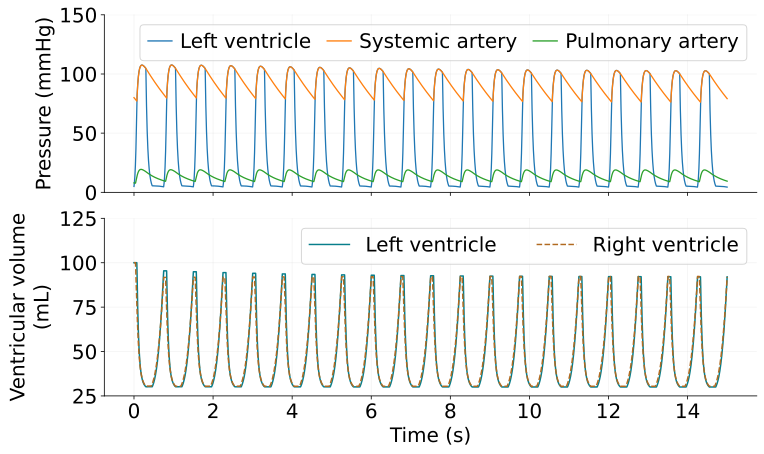

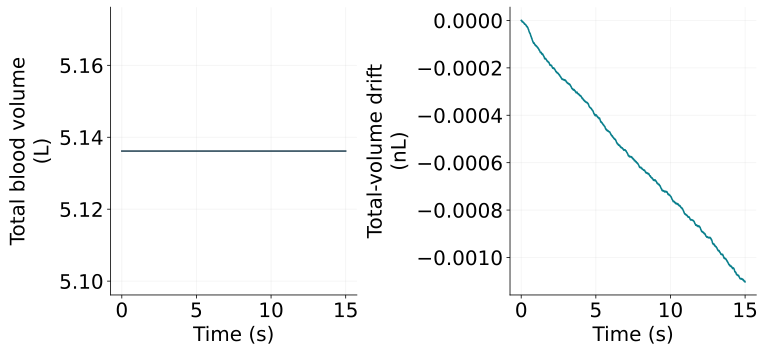

In [1]:
import demo
import numpy as np
from IPython.display import display, SVG
report=demo.run()
print(report)
display(SVG(filename='baseline-state.svg'))
display(SVG(filename='volume-audit.svg'))
data=np.load('baseline.npz')

## Implement the audit (required, about six minutes)
Replace `None` with the total-volume array obtained by summing `volume_L` over compartments at each time. Explain the axis you choose. Then subtract its initial value and compare with the reference diagnostic.

In [2]:
learner_total=None  # sum data['volume_L'] over compartments
if learner_total is None:
    print('Required edit: implement the summed volume audit and rerun.')
else:
    assert learner_total.shape==data['time_s'].shape
    assert abs(learner_total[0]-5.13616)<1e-12
    drift=np.max(np.abs(learner_total-learner_total[0]))
    assert drift<1e-9
    print('Maximum drift (L):',drift)

Required edit: implement the summed volume audit and rerun.


## Modify
For a short 1.5-second run, halve only the step. Predict which invariant should remain true and why the pressure endpoint need not be identical. A two-step comparison is evidence of sensitivity, not a convergence certificate.

In [3]:
coarse=demo.baseline(duration_s=1.5,dt_s=.001875)
fine=demo.baseline(duration_s=1.5,dt_s=.0009375)
print('Endpoint pressure difference:',np.max(np.abs(coarse['pressure_mmHg'][-1]-fine['pressure_mmHg'][-1])))
print('Volume drifts:',coarse['diagnostics']['max_total_drift_L'],fine['diagnostics']['max_total_drift_L'])

Endpoint pressure difference: 0.030843520199780983
Volume drifts: 1.5010215292932116e-13 3.623767952376511e-13


## Interpret
Distinguish the final-cycle pressure difference, the volume residual and the refinement difference. State one additional numerical check and one observation needed before a physiological claim.